# CSE407 Green Computing - Term Project
## Custom Qwen2.5 SnapKV + TurboQuant Integration

In [1]:
!pip install -q turboquant autoawq gptqmodel transformers datasets accelerate
!pip install -q matplotlib seaborn numpy scipy pandas
!pip install -q nltk rouge-score
!pip install -q nvidia-ml-py3 psutil
!pip install -q --force-reinstall "numpy<2.1" "scipy<1.15"

print("Environment setup complete. Restart runtime now (Runtime > Restart runtime) if you are in Colab.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.3/74.3 kB 5.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 36.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 5.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.8/121.8 kB 14.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.8/97.8 kB 10.2 MB/s eta 0:00:00
  Installing build

In [2]:
import torch
import torch.nn.functional as F
import gc
import threading
import time
import json
import os
import math
import __main__
from dataclasses import dataclass
from typing import Optional, List, Tuple

from transformers import AutoModelForCausalLM, AutoTokenizer
from transformers.cache_utils import DynamicCache
from transformers.models.qwen2.modeling_qwen2 import Qwen2Attention, apply_rotary_pos_emb, repeat_kv
from datasets import load_dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from turboquant import TurboQuantCache
import psutil

HAS_PYNVML = True
try:
    import pynvml
    pynvml.nvmlInit()
    handle = pynvml.nvmlDeviceGetHandleByIndex(0)
except Exception:
    HAS_PYNVML = False

In [3]:
# ==========================================
# 1. SNAPKV CUSTOM QWEN FORWARD PATCH
# ==========================================
__main__.USE_SNAPKV = False  # Global flag to toggle eviction

def custom_snapkv_forward(
    self,
    hidden_states: torch.Tensor,
    attention_mask: torch.Tensor | None = None,
    position_ids: torch.LongTensor | None = None,
    past_key_value: DynamicCache | None = None,
    output_attentions: bool = False,
    use_cache: bool = False,
    cache_position: torch.LongTensor | None = None,
    position_embeddings: tuple | None = None,
    **kwargs,
):
    bsz, q_len, _ = hidden_states.size()

    num_heads = getattr(self, "num_heads", self.config.num_attention_heads)
    num_kv_heads = getattr(self, "num_key_value_heads", self.config.num_key_value_heads)
    hidden_size = getattr(self, "hidden_size", self.config.hidden_size)
    head_dim = getattr(self, "head_dim", hidden_size // num_heads)
    num_kv_groups = num_heads // num_kv_heads

    query_states = self.q_proj(hidden_states)
    key_states = self.k_proj(hidden_states)
    value_states = self.v_proj(hidden_states)

    query_states = query_states.view(bsz, q_len, num_heads, head_dim).transpose(1, 2)
    key_states = key_states.view(bsz, q_len, num_kv_heads, head_dim).transpose(1, 2)
    value_states = value_states.view(bsz, q_len, num_kv_heads, head_dim).transpose(1, 2)

    if position_embeddings is not None:
        cos, sin = position_embeddings
    elif "position_embeddings" in kwargs:
        cos, sin = kwargs["position_embeddings"]
    else:
        cos, sin = self.rotary_emb(value_states, position_ids)

    query_states, key_states = apply_rotary_pos_emb(query_states, key_states, cos, sin)

    OBS_WINDOW = 32
    MAX_CAPACITY = 1024
    SINK_TOKENS = 4

    if getattr(__main__, 'USE_SNAPKV', False) and past_key_value is not None and q_len > MAX_CAPACITY:
        # SnapKV: Calculate importance using the observation window
        obs_queries = query_states[:, :, -OBS_WINDOW:, :]
        key_states_rep = repeat_kv(key_states, num_kv_groups)
        attn_weights_obs = torch.matmul(obs_queries, key_states_rep.transpose(2, 3)) / math.sqrt(head_dim)

        # Global token importance score
        global_scores = attn_weights_obs.sum(dim=2).sum(dim=1)  # shape: [bsz, kv_len]

        # Protect sinks and observation window
        global_scores[:, :SINK_TOKENS] = float('inf')
        global_scores[:, -OBS_WINDOW:] = float('inf')

        # Select top tokens
        _, top_indices = torch.topk(global_scores, MAX_CAPACITY, dim=-1)
        keep_indices, _ = torch.sort(top_indices, dim=-1)

        # Slice BEFORE caching
        sliced_key_states = key_states[:, :, keep_indices[0], :]
        sliced_value_states = value_states[:, :, keep_indices[0], :]

        # Full attention for accurate generation output
        attn_weights = torch.matmul(query_states, key_states_rep.transpose(2, 3)) / math.sqrt(head_dim)
        if attention_mask is not None:
            attn_weights = attn_weights + attention_mask
        attn_weights = F.softmax(attn_weights, dim=-1, dtype=torch.float32).to(query_states.dtype)
        value_states_rep = repeat_kv(value_states, num_kv_groups)
        attn_output = torch.matmul(attn_weights, value_states_rep)

        # Push SLICED tokens to cache (Works beautifully with TurboQuant!)
        past_key_value.update(sliced_key_states, sliced_value_states, self.layer_idx, {"cache_position": cache_position})

    else:
        # Standard workflow
        if past_key_value is not None:
            key_states, value_states = past_key_value.update(key_states, value_states, self.layer_idx, {"cache_position": cache_position})

        key_states_rep = repeat_kv(key_states, num_kv_groups)
        value_states_rep = repeat_kv(value_states, num_kv_groups)

        attn_weights = torch.matmul(query_states, key_states_rep.transpose(2, 3)) / math.sqrt(head_dim)
        if attention_mask is not None:
            diff = attention_mask.shape[-1] - key_states.shape[-2]
            if diff > 0:
                attention_mask = attention_mask[:, :, :, diff:]
            attn_weights = attn_weights + attention_mask

        attn_weights = F.softmax(attn_weights, dim=-1, dtype=torch.float32).to(query_states.dtype)
        attn_output = torch.matmul(attn_weights, value_states_rep)

    attn_output = attn_output.transpose(1, 2).contiguous()
    attn_output = attn_output.reshape(bsz, q_len, hidden_size)
    attn_output = self.o_proj(attn_output)

    if output_attentions:
        return attn_output, attn_weights
    else:
        return attn_output, None

Qwen2Attention.forward = custom_snapkv_forward
print("Qwen2Attention successfully patched with SnapKV!")

Qwen2Attention successfully patched with SnapKV!


In [4]:
# ==========================================
# 2. BUGFIX & METRICS MONITORS
# ==========================================
_orig_tq_init = TurboQuantCache.__init__
def _patched_tq_init(self, key_bits=4, value_bits=4, protected_layers=None, **kwargs):
    self.key_bits = key_bits
    self.value_bits = value_bits
    self.protected_layers = protected_layers or []
    kwargs.pop("key_bits", None)
    kwargs.pop("value_bits", None)
    kwargs.pop("protected_layers", None)
    _orig_tq_init(self, **kwargs)
TurboQuantCache.__init__ = _patched_tq_init

@dataclass
class ExperimentResult:
    config_name: str
    context_length: int
    peak_vram_mb: float
    inference_time_s: float
    tokens_per_second: float
    perplexity: float
    needle_found: bool
    avg_power_w: float = 0.0
    energy_estimate_j: float = 0.0

class GPUMonitor:
    def __init__(self):
        self.power_samples = []
        self._monitoring = False
        self._thread = None

    def _poll(self):
        while self._monitoring:
            if HAS_PYNVML:
                try:
                    power_mw = pynvml.nvmlDeviceGetPowerUsage(handle)
                    self.power_samples.append(power_mw / 1000.0)
                except Exception:
                    pass
            time.sleep(0.1)

    def start(self):
        self.power_samples = []
        self._monitoring = True
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()
        self._thread = threading.Thread(target=self._poll, daemon=True)
        self._thread.start()

    def stop(self):
        self._monitoring = False
        if self._thread is not None:
            self._thread.join(timeout=2)
        torch.cuda.synchronize()
        peak_vram = torch.cuda.max_memory_allocated() / (1024 ** 2)
        avg_power = np.mean(self.power_samples) if self.power_samples else 0.0
        return {"peak_vram_mb": peak_vram, "avg_power_w": avg_power}

def clear_cache():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.synchronize()

In [6]:
# ==========================================
# 3. EVALUATION HELPERS
# ==========================================
def compute_perplexity(model, tokenizer, texts, max_length=512):
    model.eval()
    total_loss, total_tokens = 0.0, 0
    for text in texts:
        tok = tokenizer(text, return_tensors="pt", truncation=True, max_length=max_length)
        tok = {k: v.to(model.device) for k, v in tok.items()}
        with torch.no_grad():
            out = model(**tok, labels=tok["input_ids"])
            total_loss += out.loss.item() * tok["input_ids"].numel()
            total_tokens += tok["input_ids"].numel()
        clear_cache()
    return np.exp(total_loss / total_tokens) if total_tokens > 0 else float("inf")

def create_needle_haystack(needle, context_length, tokenizer):
    unit = "The history of computing is a fascinating journey through time. From the earliest mechanical calculators to modern quantum computers, humanity has constantly pushed the boundaries of what machines can do. "
    sys_msg = "You are an expert at information retrieval. Below is a document. Please extract the specific information requested at the end."
    question = "Based on the document above, what is the secret project code name? Answer concisely."

    overhead = 150
    avail_tokens = max(context_length // 2, context_length - overhead)
    num_units = max(1, avail_tokens // 45)

    haystack_list = [unit] * num_units

    # Best practice: place needle at 50% depth (middle) to test 'Lost in the Middle' properly
    insert_idx = int(num_units * 0.50)
    # FIXED: Use triple quotes for multi-line f-strings
    haystack_list.insert(insert_idx, f"""

[IMPORTANT NOTICE: The secret project code name is {needle}]

""")

    full_doc = "".join(haystack_list)

    messages = [
        {"role": "system", "content": sys_msg},
        {"role": "user", "content": f"""Document:
{full_doc}

Question: {question}"""}
    ]

    full_prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    return full_prompt

def check_needle(needle, response):
    return "shadow-8821" in response.lower()

In [7]:
# ==========================================
# 4. LOADERS
# ==========================================
tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-1.5B-Instruct", trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

def load_bf16_model():
    clear_cache()
    model = AutoModelForCausalLM.from_pretrained(
        "Qwen/Qwen2.5-1.5B-Instruct",
        torch_dtype=torch.bfloat16,
        device_map="auto",
        trust_remote_code=True,
        attn_implementation="eager" # Force Qwen2Attention
    )
    model.eval()
    return model

def load_awq_model():
    clear_cache()
    model = AutoModelForCausalLM.from_pretrained(
        "Qwen/Qwen2.5-1.5B-Instruct-AWQ",
        device_map="auto",
        trust_remote_code=True,
        attn_implementation="eager" # Force Qwen2Attention
    )
    model.eval()
    return model

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

In [8]:
# ==========================================
# 5. EXPERIMENT RUNNER
# ==========================================
def run_experiment(cfg, ctx_len, monitor):
    name = cfg["name"]
    __main__.USE_SNAPKV = cfg["snapkv"]

    print(f"\n{'='*60}")
    print(f"Running: {name} @ {ctx_len} tokens")
    print(f"{'='*60}")

    model = load_awq_model() if cfg["model"] == "awq" else load_bf16_model()

    prompt = create_needle_haystack(NEEDLE, ctx_len, tokenizer)
    inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=ctx_len).to(model.device)
    actual = inputs["input_ids"].shape[1]

    tq_cache = None
    if cfg["tq"]:
        tq_cache = TurboQuantCache(key_bits=4, value_bits=4)

    monitor.start()
    t0 = time.time()

    gen_kwargs = {"max_new_tokens": 30, "do_sample": False, "pad_token_id": tokenizer.eos_token_id}
    if cfg["tq"]:
        gen_kwargs["past_key_values"] = tq_cache

    with torch.no_grad():
        out = model.generate(**inputs, **gen_kwargs)

    response = tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)
    print(f"  [Needle Response]: {response.strip()}")

    elapsed = time.time() - t0
    stats = monitor.stop()

    needle_ok = check_needle(NEEDLE, response)
    ppl = compute_perplexity(model, tokenizer, wiki_samples[:3], max_length=512)

    result = ExperimentResult(
        config_name=name, context_length=actual,
        peak_vram_mb=stats["peak_vram_mb"],
        inference_time_s=elapsed,
        tokens_per_second=30 / elapsed if elapsed > 0 else 0,
        perplexity=ppl, needle_found=needle_ok,
        avg_power_w=stats["avg_power_w"],
        energy_estimate_j=stats["avg_power_w"] * elapsed,
    )

    print(f"  Time: {elapsed:.2f}s | VRAM: {result.peak_vram_mb:.0f}MB | PPL: {ppl:.2f} | Needle: {'YES' if needle_ok else 'NO'} | Energy: {result.energy_estimate_j:.1f}J")

    del model
    if tq_cache is not None:
        del tq_cache
    clear_cache()
    return result

QUICK_TEST = True
CONTEXT_LENGTHS = [512, 2048, 8192] if QUICK_TEST else [512, 1024, 2048, 4096, 8192]
NEEDLE = "The secret project code name is SHADOW-8821"

print("Loading WikiText-2...")
try:
    wikitext = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="test")
    wiki_samples = [x["text"] for x in wikitext if len(x["text"].strip()) > 100][:20]
except Exception:
    wiki_samples = ["The quick brown fox jumps over the lazy dog. " * 10] * 3

CONFIGS = [
    {"name": "C0_Baseline_BF16", "model": "bf16", "snapkv": False, "tq": False},
    {"name": "C1_AWQ_Only",      "model": "awq",  "snapkv": False, "tq": False},
    {"name": "C2_AWQ_TQ4",       "model": "awq",  "snapkv": False, "tq": True},
    {"name": "C3_AWQ_SnapKV",    "model": "awq",  "snapkv": True,  "tq": False},
    {"name": "C4_Ultimate_SLM",  "model": "awq",  "snapkv": True,  "tq": True},
]

monitor = GPUMonitor()
all_results = []

for cfg in CONFIGS:
    for cl in CONTEXT_LENGTHS:
        try:
            r = run_experiment(cfg, cl, monitor)
            all_results.append(r)
        except Exception as e:
            print(f"  ERROR {cfg['name']} @ {cl}: {type(e).__name__}: {e}")
            import traceback
            traceback.print_exc()
        finally:
            clear_cache()

Loading WikiText-2...


README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…):   0%|          | 0.00/733k [00:00<?, ?B/s]

wikitext-2-raw-v1/train-00000-of-00001.p(…):   0%|          | 0.00/6.36M [00:00<?, ?B/s]

wikitext-2-raw-v1/validation-00000-of-00(…):   0%|          | 0.00/657k [00:00<?, ?B/s]

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

... (77 outputs left out)

INFO  Kernel: selected -> `AwqExllamaV2Linear`.                                


Loading weights:   0%|          | 0/731 [00:00<?, ?it/s]

INFO  gc.collect() reclaimed 6373 objects in 0.298s                            


  [Needle Response]: !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
  Time: 4.92s | VRAM: 6030MB | PPL: nan | Needle: NO | Energy: 291.9J


,config_name,context_length,peak_vram_mb,inference_time_s,tokens_per_second,perplexity,needle_found,avg_power_w,energy_estimate_j
0,C0_Baseline_BF16,357,2976.445801,2.608965,11.498811,13.321681,False,46.501346,121.320403
1,C0_Baseline_BF16,1513,3248.730469,2.911524,10.303884,13.321681,False,62.495964,181.958474
2,C0_Baseline_BF16,6137,7453.139648,11.184988,2.682166,13.321681,False,67.226368,751.926120
3,C1_AWQ_Only,357,1224.665527,1.909003,15.715011,NaN,False,44.597263,85.136299
4,C1_AWQ_Only,1513,2635.527344,2.117079,14.170469,NaN,False,47.486667,100.533014
5,C1_AWQ_Only,6137,6029.663086,4.746587,6.320331,NaN,False,59.734848,283.536640
6,C2_AWQ_TQ4,357,2415.637207,1.525436,19.666513,NaN,False,46.365400,70.727436
7,C2_AWQ_TQ4,1513,2635.527344,1.893030,15.847608,NaN,False,51.208421,96.939086
8,C2_AWQ_TQ4,6137,6029.663086,4.780172,6.275924,NaN,False,59.886326,286.266960
9,C3_AWQ_SnapKV,357,2416.410645,1.707747,17.567008,NaN,False,48.134941,82.202289


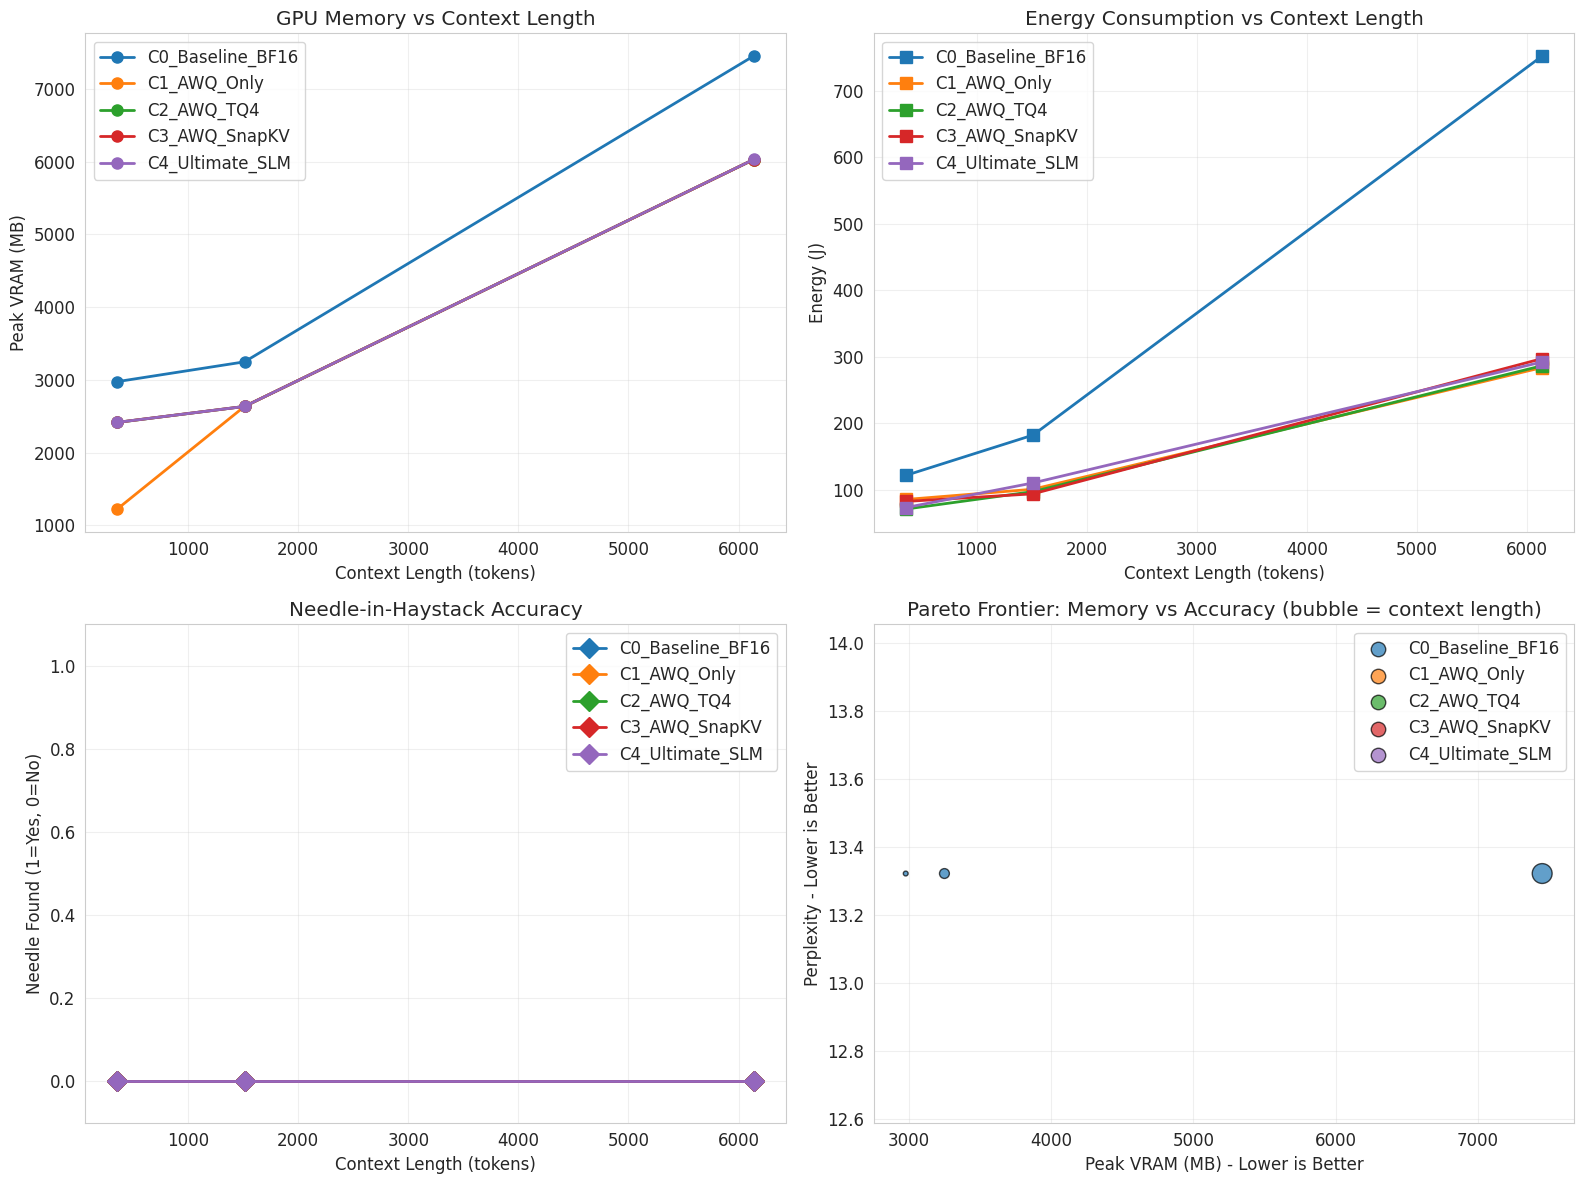

In [9]:
# ==========================================
# 6. RESULTS & VISUALIZATION
# ==========================================
df = pd.DataFrame([r.__dict__ for r in all_results])
display(df)

df.to_csv("experiment_results_corrected.csv", index=False)

sns.set_style("whitegrid")
plt.rcParams.update({"figure.figsize": (12, 8), "font.size": 12})
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: VRAM vs Context
ax = axes[0, 0]
for cn in df["config_name"].unique():
    d = df[df["config_name"] == cn].sort_values("context_length")
    ax.plot(d["context_length"], d["peak_vram_mb"], "o-", label=cn, lw=2, ms=8)
ax.set_xlabel("Context Length (tokens)"); ax.set_ylabel("Peak VRAM (MB)")
ax.set_title("GPU Memory vs Context Length"); ax.legend(); ax.grid(alpha=0.3)

# Plot 2: Energy vs Context
ax = axes[0, 1]
for cn in df["config_name"].unique():
    d = df[df["config_name"] == cn].sort_values("context_length")
    ax.plot(d["context_length"], d["energy_estimate_j"], "s-", label=cn, lw=2, ms=8)
ax.set_xlabel("Context Length (tokens)"); ax.set_ylabel("Energy (J)")
ax.set_title("Energy Consumption vs Context Length"); ax.legend(); ax.grid(alpha=0.3)

# Plot 3: Needle Accuracy
ax = axes[1, 0]
for cn in df["config_name"].unique():
    d = df[df["config_name"] == cn].sort_values("context_length")
    ax.plot(d["context_length"], d["needle_found"].astype(float), "D-", label=cn, lw=2, ms=10)
ax.set_xlabel("Context Length (tokens)"); ax.set_ylabel("Needle Found (1=Yes, 0=No)")
ax.set_title("Needle-in-Haystack Accuracy"); ax.set_ylim(-0.1, 1.1); ax.legend(); ax.grid(alpha=0.3)

# Plot 4: Pareto Frontier
ax = axes[1, 1]
for cn in df["config_name"].unique():
    d = df[df["config_name"] == cn]
    ax.scatter(d["peak_vram_mb"], d["perplexity"], s=d["context_length"] / 30, label=cn, alpha=0.7, edgecolors="black")
ax.set_xlabel("Peak VRAM (MB) - Lower is Better")
ax.set_ylabel("Perplexity - Lower is Better")
ax.set_title("Pareto Frontier: Memory vs Accuracy (bubble = context length)")
ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("experiment_results_corrected.png", dpi=150, bbox_inches="tight")
plt.show()